# 01 · Por qué hay una validación dentro del entrenamiento

**Decisión:** antes de medir en el test, cada modelo elige su variante (binaria o centrada,
número de vecinos, rasgos...) en una **validación** que sale del propio entrenamiento.
El test solo se usa al final, una vez por modelo.

Este notebook explica por qué, con los datos reales de Gold y una simulación sencilla.

## La idea, con un ejemplo

Piensa en el test como el **examen final** y en la validación como los **exámenes de práctica**.

Probamos 20 variantes. Si eligiéramos la mejor mirando el examen final, la nota de la
ganadora saldría inflada: entre muchas variantes que en realidad son casi iguales, gana
la que ha tenido **más suerte con esas preguntas concretas**. Esa suerte no se repetirá
con usuarios nuevos.

Por eso se hace en dos pasos:

| Parte | Cuánto | Para qué |
|---|---|---|
| **Ajuste** | 64 % de las notas de cada usuario | Entrenar las 20 variantes |
| **Validación** | 16 % | Elegir la mejor variante de cada familia (popularidad, contenido, item-kNN) |
| **Test** | 20 % | Medir una sola vez a las tres elegidas, ya entrenadas con ajuste + validación (80 %) |

El 20 % del test es el mismo que pide el plan: no cambia. La validación sale del 80 % restante
(un 20 % de ese 80 %, es decir, un 16 % del total).

Separar una parte del entrenamiento para elegir es lo habitual en aprendizaje automático
(*entrenamiento / validación / test*). Por ejemplo, `GridSearchCV` de scikit-learn hace lo
mismo con validación cruzada dentro del entrenamiento.

In [1]:
import sys
from pathlib import Path

# Raíz del repositorio en el path, para importar ml y pipeline desde notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

## La partición real

`ml.datos.preparar_valoraciones()` lee Gold, ordena las notas por usuario y juego y reparte
cada nota en una de las tres partes, al azar y con semilla fija. Tarda unos segundos.

In [2]:
import numpy as np
import pandas as pd

from ml.datos import AJUSTE, NOMBRE_PARTE, TEST, VALIDACION, origen_gold, preparar_valoraciones


def miles(n):
    return f"{int(n):,}".replace(",", ".")


print("Gold generado desde:", origen_gold())
datos = preparar_valoraciones("csv")
r = datos.resumen()
tabla = pd.DataFrame({
    "parte": [NOMBRE_PARTE[p] for p in (AJUSTE, VALIDACION, TEST)],
    "valoraciones": [r[f"valoraciones_{NOMBRE_PARTE[p]}"] for p in (AJUSTE, VALIDACION, TEST)],
})
tabla["porcentaje"] = (100 * tabla["valoraciones"] / r["valoraciones"]).round(1)
print(f"{miles(r['valoraciones'])} valoraciones de {miles(r['usuarios'])} usuarios "
      f"sobre {miles(r['juegos'])} juegos")
tabla

Gold generado desde: bronze
18.340.325 valoraciones de 224.558 usuarios sobre 21.924 juegos


,parte,valoraciones,porcentaje
0,ajuste,11734722,64.0
1,validacion,2938867,16.0
2,test,3666736,20.0


El reparto se hace **dentro de cada usuario**: todos tienen notas en las tres partes.
Un usuario con el mínimo de Gold (10 notas) queda con 6 de ajuste, 2 de validación y 2 de test.

In [3]:
por_usuario = pd.crosstab(datos.fila, datos.parte, rownames=["usuario"], colnames=[None])
por_usuario = por_usuario.rename(columns=NOMBRE_PARTE)
por_usuario["total"] = por_usuario.sum(axis=1)
print("Usuarios sin ninguna nota en alguna parte:",
      int((por_usuario[["ajuste", "validacion", "test"]] == 0).any(axis=1).sum()))
por_usuario.groupby("total").first().head(5)   # cómo queda un usuario según cuántas notas tiene

Usuarios sin ninguna nota en alguna parte: 0


,ajuste,validacion,test
total,,,
10,6,2,2
11,7,2,2
12,8,2,2
13,8,2,3
14,9,2,3


## Cuánto se infla la ganadora si se elige en el test

Una simulación: 20 variantes con **exactamente la misma calidad real**. Cada una se mide
con ruido, porque la muestra de usuarios es finita. Si nos quedamos con la que mejor sale,
su nota está por encima de la real: ese exceso es el **optimismo** de elegir y medir con los
mismos datos.

Es el caso más desfavorable, porque supone que el error de cada variante es independiente.
En la práctica todas se miden con los mismos usuarios, sus errores se parecen y el optimismo
es algo menor.

El ruido de la medida depende de cuánto varía el NDCG@10 entre usuarios. Lo tomamos de los
datos: la desviación del NDCG@10 de la popularidad en la validación.

In [4]:
from siguiente_partida.metricas import metricas_por_usuario
from siguiente_partida.recomendadores import Popularidad

R = datos.matriz(AJUSTE)
rel = datos.relevantes(VALIDACION)
filas = np.flatnonzero(np.diff(rel.indptr) > 0)
top, _ = Popularidad().ajustar(R).recomendar(R[filas], k=10)
ndcg = metricas_por_usuario(top, rel[filas])["ndcg"]
sigma = float(np.std(ndcg))
print(f"Usuarios evaluables: {miles(len(filas))}   desviación del NDCG@10 entre usuarios: {sigma:.3f}")

Usuarios evaluables: 221.726   desviación del NDCG@10 entre usuarios: 0.154


In [5]:
rng = np.random.default_rng(0)
N_VARIANTES, REPETICIONES = 20, 4000
tamanos = np.unique(np.geomspace(100, len(filas), 25).astype(int))
optimismo = []
for n in tamanos:
    error = rng.normal(0, sigma / np.sqrt(n), (REPETICIONES, N_VARIANTES))  # error de medida
    optimismo.append(error.max(axis=1).mean())        # la ganadora: la de más suerte
optimismo = np.array(optimismo)
print(f"Optimismo con {miles(tamanos[-1])} usuarios: +{optimismo[-1]:.4f} de NDCG@10")
print(f"Optimismo con 1.000 usuarios: +{np.interp(1000, tamanos, optimismo):.4f}")

Optimismo con 221.726 usuarios: +0.0006 de NDCG@10
Optimismo con 1.000 usuarios: +0.0092


In [6]:
import matplotlib.pyplot as plt

# Colores y estilo comunes de las figuras
SERIE = ["#2a78d6", "#eb6834", "#1baf7a"]          # azul, naranja, aguamarina
TEXTO, TEXTO_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "axes.edgecolor": REJILLA,
    "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 8,
})

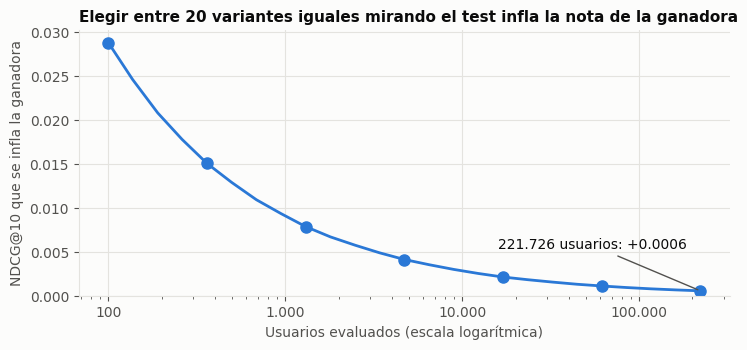

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(tamanos, optimismo, color=SERIE[0], marker="o", markevery=4)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: miles(x))
ax.set_xlabel("Usuarios evaluados (escala logarítmica)")
ax.set_ylabel("NDCG@10 que se infla la ganadora")
ax.set_title("Elegir entre 20 variantes iguales mirando el test infla la nota de la ganadora")
ax.annotate(f"{miles(tamanos[-1])} usuarios: +{optimismo[-1]:.4f}",
            (tamanos[-1], optimismo[-1]), xytext=(-10, 30), textcoords="offset points",
            ha="right", color=TEXTO, arrowprops={"arrowstyle": "-", "color": TEXTO_2})
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

## Conclusión

- Con todos los usuarios de Gold el optimismo es pequeño (la cifra exacta sale arriba).
  Pero las diferencias entre variantes parecidas también lo son: en la validación del lote
  20261120-190950, el item-kNN con 10 vecinos supera al de 25 por solo 0,0009 de NDCG@10
  (notebook 02). Con diferencias de ese tamaño, elegir en el test no permitiría saber si la
  ganadora es mejor o solo ha tenido suerte con esos usuarios.
- Con la validación, la cifra del test es **limpia**: ninguna decisión se ha tomado mirándola.
  Así la comparación con la popularidad (que no tiene nada que elegir) es justa.
- El coste es pequeño: las variantes se entrenan con un 64 % en vez de un 80 %, y las tres
  elegidas se vuelven a entrenar con el 80 % antes del test.

El código está en `ml/evaluar.py` (fases `validacion` y `test`). La elección concreta de
cada familia se explica en `02_eleccion_de_variantes.ipynb`.